In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_style("whitegrid")

In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nOverall survival rate:", round(df["Survived"].mean() * 100, 2), "%")
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


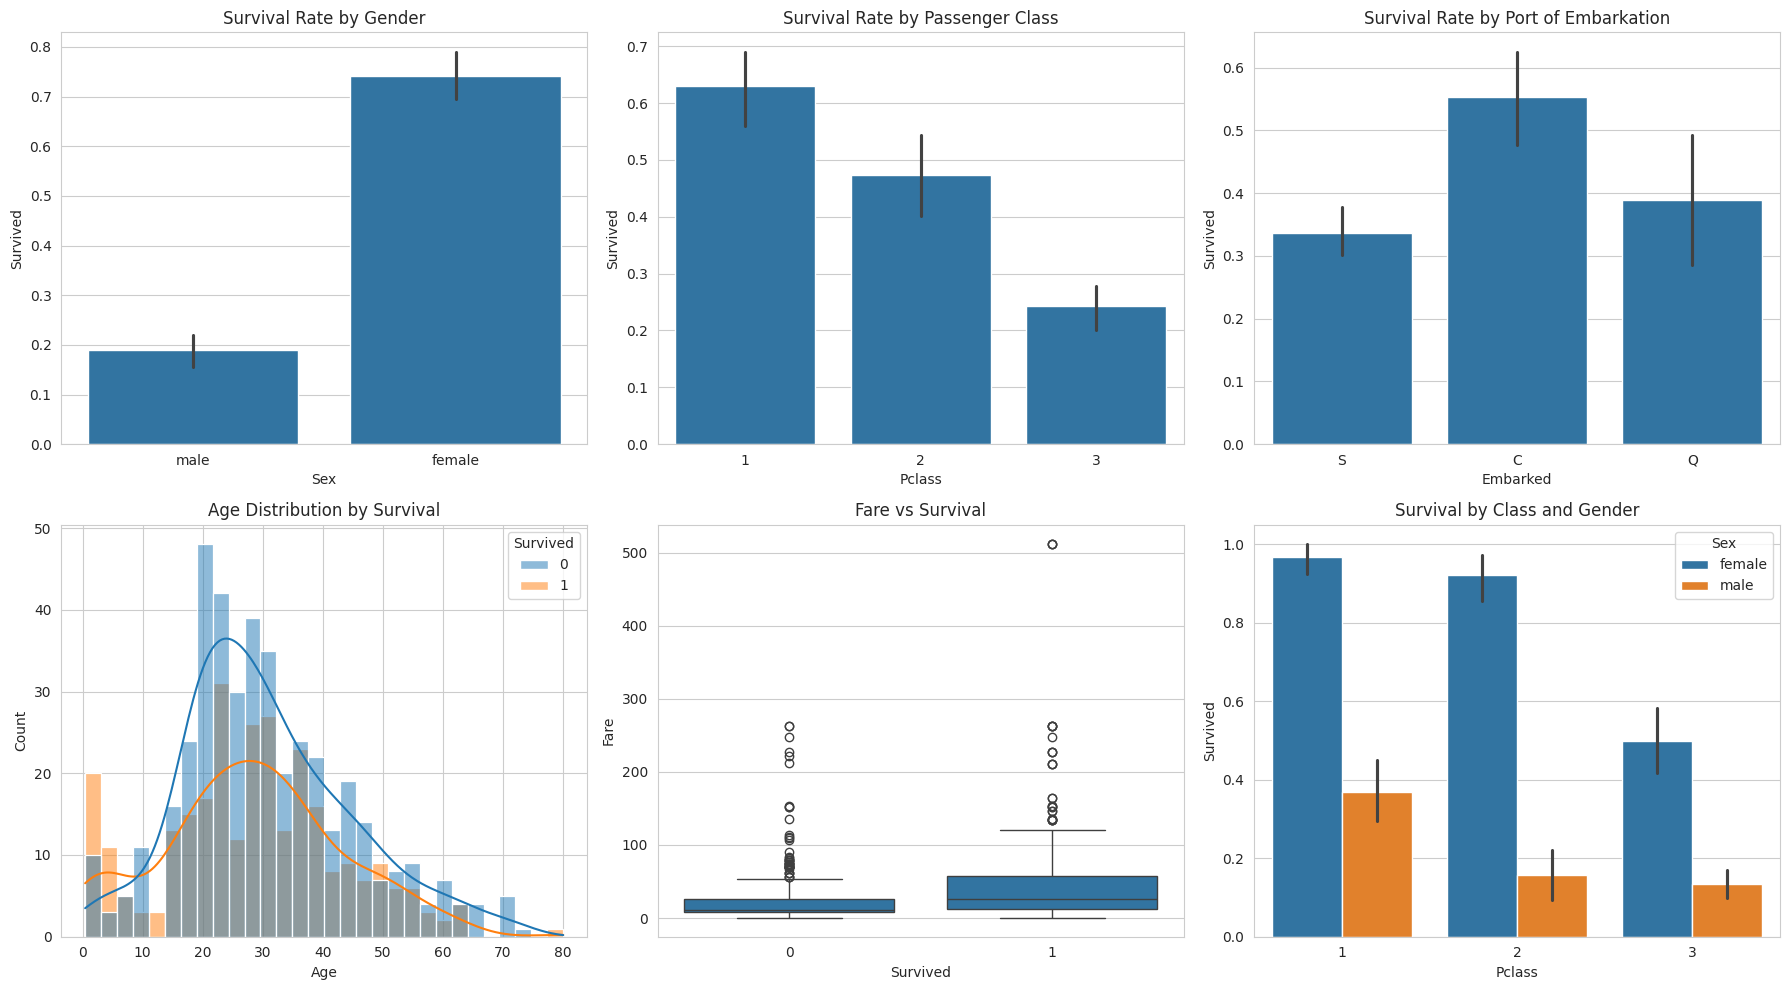

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.barplot(x="Sex", y="Survived", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Survival Rate by Gender")

sns.barplot(x="Pclass", y="Survived", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Survival Rate by Passenger Class")

sns.barplot(x="Embarked", y="Survived", data=df, ax=axes[0, 2])
axes[0, 2].set_title("Survival Rate by Port of Embarkation")

sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Age Distribution by Survival")

sns.boxplot(x="Survived", y="Fare", data=df, ax=axes[1, 1])
axes[1, 1].set_title("Fare vs Survival")

sns.barplot(x="Pclass", y="Survived", hue="Sex", data=df, ax=axes[1, 2])
axes[1, 2].set_title("Survival by Class and Gender")

plt.tight_layout()
plt.show()

In [5]:
data = df.copy()

# Extract title from name (Mr, Mrs, Miss, Master...)
data["Title"] = data["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
data["Title"] = data["Title"].replace(["Mlle", "Ms"], "Miss").replace("Mme", "Mrs")
rare_titles = data["Title"].value_counts()[lambda s: s < 10].index
data["Title"] = data["Title"].replace(rare_titles, "Rare")

# Family features
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

# Handle missing values
data["Age"] = data["Age"].fillna(data.groupby("Title")["Age"].transform("median"))
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])
data["Fare"] = data["Fare"].fillna(data["Fare"].median())

# Drop columns that aren't useful
data = data.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

# Encode categorical columns
data = pd.get_dummies(data, columns=["Sex", "Embarked", "Title"],
                      drop_first=True, dtype=int)

print("Remaining missing values:", data.isnull().sum().sum())
data.head()

Remaining missing values: 0


,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,22.0,1,0,7.2500,2,0,1,0,1,0,1,0,0
1,1,1,38.0,1,0,71.2833,2,0,0,0,0,0,0,1,0
2,1,3,26.0,0,0,7.9250,1,1,0,0,1,1,0,0,0
3,1,1,35.0,1,0,53.1000,2,0,0,0,1,0,0,1,0
4,0,3,35.0,0,0,8.0500,1,1,1,0,1,0,1,0,0


In [6]:
X = data.drop("Survived", axis=1)
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (712, 14) | Test: (179, 14)


In [7]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cv = cross_val_score(model, X, y, cv=5).mean()
    results.append({
        "Model": name,
        "Test Accuracy": round(accuracy_score(y_test, pred), 4),
        "CV Accuracy (5-fold)": round(cv, 4),
    })

results_df = pd.DataFrame(results).sort_values("Test Accuracy", ascending=False)
results_df

,Model,Test Accuracy,CV Accuracy (5-fold)
0,Logistic Regression,0.8547,0.8238
2,Random Forest,0.8380,0.8249
1,Decision Tree,0.7989,0.8025


                 precision    recall  f1-score   support

Did not survive       0.84      0.91      0.87       110
       Survived       0.83      0.72      0.78        69

       accuracy                           0.84       179
      macro avg       0.84      0.82      0.82       179
   weighted avg       0.84      0.84      0.84       179



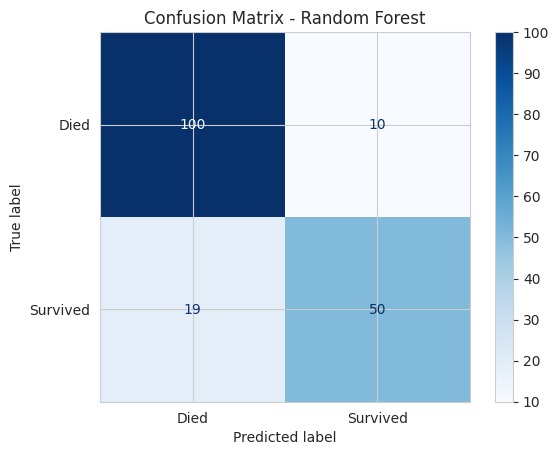

In [8]:
rf = models["Random Forest"]
y_pred = rf.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"]))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Died", "Survived"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.show()

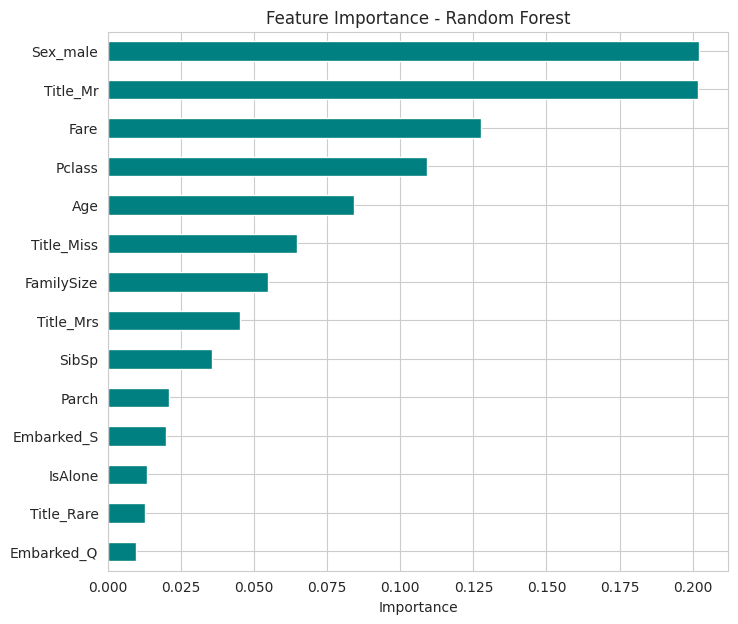

Sex_male    0.202032
Title_Mr    0.201856
Fare        0.127463
Pclass      0.108960
Age         0.084190
dtype: float64


In [9]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 7))
importances.plot(kind="barh", color="teal")
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.show()

print(importances.sort_values(ascending=False).head(5))

In [10]:
def predict_passenger(pclass, sex, age, sibsp, parch, fare, embarked, title):
    row = dict.fromkeys(X.columns, 0)
    row.update({
        "Pclass": pclass, "Age": age, "SibSp": sibsp, "Parch": parch,
        "Fare": fare, "FamilySize": sibsp + parch + 1,
        "IsAlone": int(sibsp + parch == 0),
    })
    if sex == "male":
        row["Sex_male"] = 1
    for col in (f"Embarked_{embarked}", f"Title_{title}"):
        if col in row:
            row[col] = 1
    prob = rf.predict_proba(pd.DataFrame([row])[X.columns])[0][1]
    print(f"Survival probability: {prob:.2%} -> {'Survived' if prob >= 0.5 else 'Did not survive'}")

# Examples
predict_passenger(1, "female", 28, 0, 0, 80, "S", "Miss")
predict_passenger(3, "male", 30, 0, 0, 8, "S", "Mr")

Survival probability: 96.30% -> Survived
Survival probability: 11.27% -> Did not survive
